# Kinematic Model: preprocessing

Step 2 of the project (Prospect Profile) models how players move. This notebook turns the raw in-game tracking (`game_tracking_2023/2024/2025.csv`) into a padded tensor with one sample per player × play and one channel per tracking variable.

The helper functions are in [`utils/tracking.py`](../utils/tracking.py).

In [1]:
import sys
import os
from os import path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# make the repo root importable so `utils` resolves from notebooks/
sys.path.insert(0, path.abspath(".."))
from utils import tracking as trk

# Dataset

In [2]:
import kagglehub

DATA_DIR = kagglehub.competition_download("nfl-big-data-bowl-2027")
DATA_DIR = path.join(DATA_DIR, "nfl-big-data-bowl-2027")
SEASONS = [2023, 2024, 2025]

/home/arthur/miniconda3/envs/ml/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
players_df = pd.read_csv(path.join(DATA_DIR, "players.csv"))
plays_df = pd.read_csv(
    path.join(DATA_DIR, "player_play.csv"),
    usecols=trk.KEYS + ["play_direction", "play_nullified_by_penalty", "route_ran"],
)
players_df[players_df["nfl_position"].isin(trk.SKILL_POSITIONS)]["nfl_position"].value_counts()

nfl_position
WR    106
CB     60
TE     42
SS     28
FS     25
DB      5
RB      1
FB      1
Name: count, dtype: int64

# Preprocessing

**Scope.** All skill-position prospects (WR, TE, RB, FB, CB, SS, FS, DB). Plays nullified by penalty are removed. Unlike the Usage Profile, **preseason games are kept**: preseason doesn't reflect a player's real role, but it is still valid movement data.

**1. Temporal alignment.** The raw files are not sorted. Each track (player × play) is sorted by timestamp, and t = 0 is set at the `ball_snap` frame. The ~1 s of pre-snap frames is dropped, as are tracks with no snap. The tracking runs at 10 Hz, so the frame index is `round(t / 0.1)`. If a raw frame is missing, the gap stays in place (as padding) instead of shifting the rest of the track.

**2. Geometric normalization.** Offense attacks toward the left on some plays and toward the right on others. Plays going left are rotated 180° (`x → 120 − x`, `y → 53.3 − y`, `dir` and `o` + 180°), so every play moves toward +x. Each track is then translated so the player's position at the snap is the origin (0, 0), which removes absolute field position.

**3. Tensor.** Tracks are packed into `X` with shape `(N, T, C)`, using T = 100 frames (10 s after the snap). Shorter tracks are zero-padded, longer ones are truncated, and a boolean `mask` marks the real frames. The angles `dir` and `o` are encoded as sin/cos pairs so they stay continuous across 0°/360°.

In [4]:
series_df = trk.build_tracking_series(DATA_DIR, SEASONS, plays_df, players_df)
series_df.shape

2023: 22253 skill tracks -> 21369 not nullified -> 21329 with snap -> 21329 with play_direction


2024: 49926 skill tracks -> 47764 not nullified -> 47730 with snap -> 47730 with play_direction


2025: 67080 skill tracks -> 64002 not nullified -> 63892 with snap -> 63891 with play_direction


(8457421, 17)

## Sanity checks

In [5]:
tracks = series_df.groupby(trk.KEYS)
first = tracks.first()
assert (first["frame"] == 0).all()
assert (first[["x_rel", "y_rel"]] == 0).all().all()
print("tracks:", len(first), "| tracks with a missing frame:", int((tracks["frame"].max() + 1 != tracks.size()).sum()))
print("post-snap length (frames):")
tracks.size().describe()

tracks: 132950 | tracks with a missing frame: 1
post-snap length (frames):


count    132950.000000
mean         63.613546
std          17.110732
min          13.000000
25%          52.000000
50%          61.000000
75%          72.000000
max         377.000000
dtype: float64

**Direction.** Two seconds after the snap, route runners should have moved downfield (+x) by the same amount, whichever way the play originally went.

In [6]:
routes = series_df.merge(plays_df[trk.KEYS + ["route_ran"]].dropna(), on=trk.KEYS)
routes[routes["frame"] == 20].groupby("play_direction")["x_rel"].mean()

play_direction
left     5.807448
right    5.839270
Name: x_rel, dtype: float32

**Heading.** After the rotation, the velocity computed from the positions should still agree with the reported speed and direction, vx = s·sin(dir), vy = s·cos(dir).

In [7]:
sample = series_df[series_df.set_index(trk.KEYS).index.isin(first.sample(500, random_state=0).index)]
err = []
for _, t in sample.groupby(trk.KEYS):
    if len(t) < 3:
        continue
    vx, vy = np.gradient(t["x_rel"], trk.DT), np.gradient(t["y_rel"], trk.DT)
    d = np.deg2rad(t["dir"])
    err.append(np.hypot(vx - t["s"] * np.sin(d), vy - t["s"] * np.cos(d)).mean())
print(f"median velocity error: {np.median(err):.3f} yd/s")

median velocity error: 0.068 yd/s


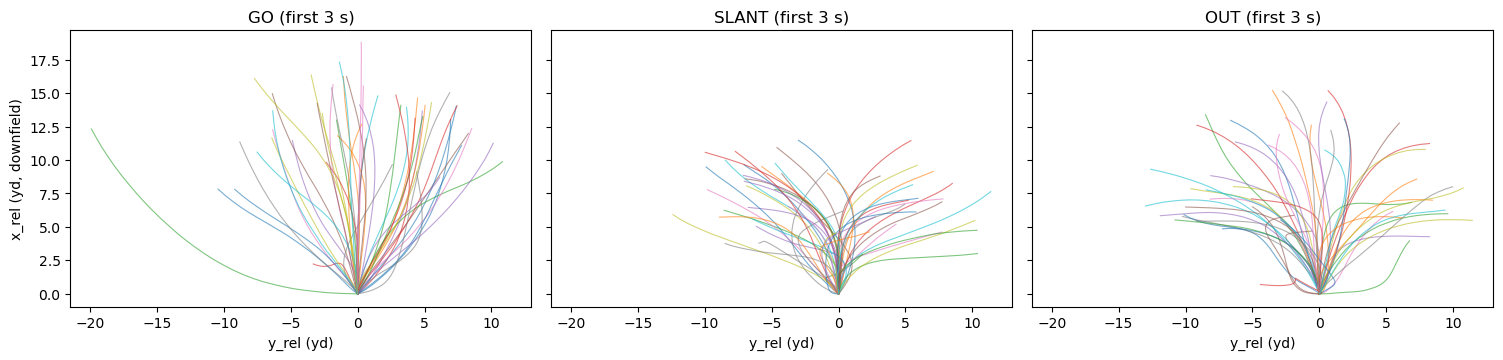

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for ax, route in zip(axes, ["GO", "SLANT", "OUT"]):
    ids = routes.loc[routes["route_ran"] == route, trk.KEYS].drop_duplicates().sample(50, random_state=0)
    for _, t in routes.merge(ids, on=trk.KEYS).groupby(trk.KEYS):
        t = t[t["frame"] <= 30]  # first 3 s
        ax.plot(t["y_rel"], t["x_rel"], lw=0.8, alpha=0.6)
    ax.set_title(f"{route} (first 3 s)")
    ax.set_xlabel("y_rel (yd)")
    ax.set_aspect("equal")
axes[0].set_ylabel("x_rel (yd, downfield)")
plt.tight_layout()

## Tensor

In [9]:
X, mask, channels = trk.to_tensor(series_df, max_len=100)

assert X.shape[1:] == (100, len(channels))
assert (X[~mask] == 0).all()
assert (X[:, 0, :2] == 0).all()
for a in ("dir", "o"):
    s, c = channels.index(f"{a}_sin"), channels.index(f"{a}_cos")
    assert torch.allclose((X[..., s] ** 2 + X[..., c] ** 2)[mask], torch.tensor(1.0), atol=1e-5)

# round trip: the first track in the tensor matches its rows in the long frame (to_tensor sorts by KEYS)
key = first.index[0]
t = series_df.set_index(trk.KEYS).loc[key]
t = t[t["frame"] < 100]
assert np.allclose(X[0, torch.from_numpy(t["frame"].to_numpy().copy()).long(), 0].numpy(), t["x_rel"].to_numpy())

print("X:", tuple(X.shape), "| channels:", channels)
print(f"truncated tracks: {(tracks.size() > 100).sum()} | padding: {1 - mask.float().mean():.1%} | size: {X.numel() * 4 / 1e9:.2f} GB")

X: (132950, 100, 9) | channels: ['x_rel', 'y_rel', 's', 'a', 'dis', 'dir_sin', 'dir_cos', 'o_sin', 'o_cos']
truncated tracks: 4177 | padding: 36.9% | size: 0.48 GB


# Save

In [10]:
OUT_DIR = path.abspath("../data/processed/kinematics")
os.makedirs(OUT_DIR, exist_ok=True)
out_path = path.join(OUT_DIR, "tracking_tensor.pt")
torch.save({"X": X, "mask": mask, "channels": channels}, out_path)

loaded = torch.load(out_path)
assert torch.equal(loaded["X"], X) and torch.equal(loaded["mask"], mask) and loaded["channels"] == channels